# Zusatz Z1 – Speicherformate CSV und Parquet im Vergleich

**Fragestellung (Unterricht 30.09.2026, Bonus):** Wie groß sind dieselben Tabellen als CSV und als Parquet? Ändert sich die Dateigröße, wenn die Tabelle vorher nach einer anderen Spalte sortiert wird (`zeit_utc` bzw. `flow_ein`)?

**Daten:** neueste bereinigte Versionen aus `silver/cleaned/<stadt>/flow/` und `…/wetter/` (nur lesen).
**Ablage der Testdateien:** temporärer Ordner, wird nach dem Lauf gelöscht – der Data Lake bleibt unverändert.
**Erwartung laut Recherche:** Parquet speichert spaltenweise und komprimiert (Standard Snappy) → deutlich kleiner als CSV [Q1]. Sortierung verändert CSV kaum (gleiche Zeichen), bei Parquet werden gleiche/ähnliche Werte hintereinander durch Lauflängen- und Wörterbuch-Kodierung (Run-Length/Dictionary Encoding) kompakter [Q2].

In [1]:
from pathlib import Path          # Pfade
import tempfile                    # temporärer Ordner für Testdateien
import pandas as pd                # Tabellen
import matplotlib.pyplot as plt    # Grafik

STADT = "schwartau"                                   # Standort (wie N1–N4)
LAKE = Path("../02_daten_ITS-Data/lakehouse")         # lokaler Data Lake
BILD = Path("../04_images/z1_speicherformate.png")    # Ergebnisgrafik

def neueste(ordner):
    """Neueste Datei (höchster UTC-Zeitstempel im Namen) außerhalb des _archiv."""
    return sorted(p for p in ordner.glob("*.csv"))[-1]

tabellen = {
    "flow (1 Min.)": pd.read_csv(neueste(LAKE / "silver/cleaned" / STADT / "flow"), parse_dates=["zeit_utc"]),
    "wetter (1 Std.)": pd.read_csv(neueste(LAKE / "silver/cleaned" / STADT / "wetter"), parse_dates=["zeit_utc"]),
}
for name, df in tabellen.items():
    print(f"{name}: {len(df):,} Zeilen × {df.shape[1]} Spalten".replace(",", "."))

flow (1 Min.): 1.256.918 Zeilen × 7 Spalten
wetter (1 Std.): 21.145 Zeilen × 20 Spalten


In [2]:
# Jede Tabelle in 3 Sortierungen als CSV und Parquet speichern und die Dateigröße messen
sortierungen = {"flow (1 Min.)": ["zeit_utc", "flow_ein"], "wetter (1 Std.)": ["zeit_utc", "aussentemperatur_c"]}
ergebnis = []
with tempfile.TemporaryDirectory() as tmp:            # Ordner wird am Ende automatisch gelöscht
    for name, df in tabellen.items():
        for sortiert in ["unsortiert (Original)"] + sortierungen[name]:
            d = df if sortiert.startswith("unsortiert") else df.sort_values(by=sortiert, kind="stable")
            for fmt in ["CSV", "Parquet"]:
                ziel = Path(tmp) / f"test.{fmt.lower()}"
                if fmt == "CSV":
                    d.to_csv(ziel, index=False)
                else:
                    d.to_parquet(ziel, index=False)      # Standard: pyarrow, Kompression snappy
                ergebnis.append({"Tabelle": name, "Sortierung": sortiert, "Format": fmt,
                                 "Größe_MB": round(ziel.stat().st_size / 1_000_000, 2)})
ergebnis = pd.DataFrame(ergebnis)
tabelle = ergebnis.pivot_table(index=["Tabelle", "Sortierung"], columns="Format", values="Größe_MB", sort=False)
tabelle["Parquet in % von CSV"] = (tabelle["Parquet"] / tabelle["CSV"] * 100).round(1)
tabelle

Format                                   CSV  Parquet  Parquet in % von CSV
Tabelle         Sortierung                                                 
flow (1 Min.)   unsortiert (Original)  83.24    15.00                  18.0
                zeit_utc               83.24    15.00                  18.0
                flow_ein               83.24    15.50                  18.6
wetter (1 Std.) unsortiert (Original)   3.64     0.47                  12.9
                zeit_utc                3.64     0.47                  12.9
                aussentemperatur_c      3.64     0.48                  13.2

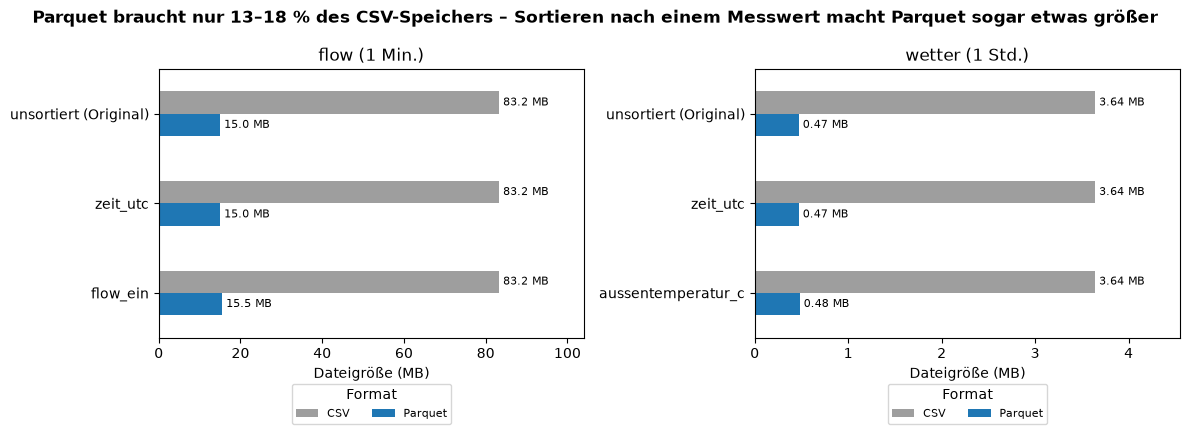

In [3]:
# Grafik nach Grafik-Standard: Titel = Aussage, Einheit, Werte an den Balken
fig, achsen = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, teil) in zip(achsen, ergebnis.groupby("Tabelle", sort=False)):
    breite = teil.pivot(index="Sortierung", columns="Format", values="Größe_MB").reindex(teil["Sortierung"].unique())
    breite.plot.barh(ax=ax, color={"CSV": "#9E9E9E", "Parquet": "#1F77B4"})
    for c in ax.containers:
        ax.bar_label(c, fmt="%.2f MB" if breite.values.max() < 10 else "%.1f MB", padding=3, fontsize=8)
    ax.set_title(name); ax.set_xlabel("Dateigröße (MB)"); ax.set_ylabel("")
    ax.invert_yaxis(); ax.margins(x=0.25)
    ax.legend(title="Format", loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=8)   # Legende unter der Achse, verdeckt keine Balken
fig.suptitle("Parquet braucht nur 13–18 % des CSV-Speichers – Sortieren nach einem Messwert macht Parquet sogar etwas größer", fontweight="bold")
fig.tight_layout(); fig.savefig(BILD, dpi=150, bbox_inches="tight"); plt.show()

## Ergebnis und Einordnung

| Tabelle | CSV | Parquet | Parquet in % von CSV | Sortiert nach Messwert |
| :-- | --: | --: | --: | :-- |
| flow (1,26 Mio. Zeilen, 7 Spalten) | 83,2 MB | 15,0 MB | 18,0 % | nach `flow_ein`: 15,5 MB (+3 %) |
| wetter (21.145 Zeilen, 20 Spalten) | 3,6 MB | 0,47 MB | 12,9 % | nach `aussentemperatur_c`: 0,48 MB (+2 %) |

- **CSV vs. Parquet:** Parquet braucht nur 13–18 % des Speichers von CSV (Faktor 5,5–7,7), weil es spaltenweise speichert und komprimiert. Erwartung bestätigt [Q1].
- **Sortierung:** CSV bleibt exakt gleich groß (dieselben Zeichen, nur andere Reihenfolge). Parquet wird nach Sortierung **nach einem Messwert** etwas **größer** (+2 bis +3 %): Die Original-Tabelle ist bereits nach Zeit sortiert – aufeinanderfolgende Zeitstempel und ähnliche Messwerte lassen sich gut kodieren. Sortiert man nach `flow_ein`, liegen gleiche flow-Werte zusammen, dafür springen Zeitstempel und alle anderen Spalten → in Summe schlechter komprimierbar. Sortierung nach `zeit_utc` ändert nichts (war schon so sortiert).
- **Folgerung für die Plattform:** Silver und Gold als Parquet ablegen (spart ca. 80–87 % Speicher und damit Speicher- und Übertragungskosten); Daten nach Zeit sortiert lassen – das ist auch die häufigste Filterspalte.
- **Einordnung:** Unsere Silver-Stufe speichert derzeit CSV (lesbar, Git-freundlich); für den Betrieb in Azure ist Parquet die bessere Wahl (Befund E7).

**Quellen**
- [Q1] Apache Parquet – Dokumentation „Compression“ und „Encodings“, parquet.apache.org/docs (abgerufen 30.09.2026)
- [Q2] pandas – `DataFrame.to_parquet` (Engine pyarrow, Standard-Kompression snappy), pandas.pydata.org (abgerufen 30.09.2026)